In [1]:
import cv2
import numpy as np
def fill_contours(path_mask):
    # Read the mask from the path
    mask = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    # Get outer contours and draw filled ones as white on a black background
    contours = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = contours[0] if len(contours) == 2 else contours[1]
    result = np.zeros_like(mask)
    
    for contour in contours:
        cv2.drawContours(result, [contour], 0, 255, -1)
    
    result = np.array(result/result.max(), dtype=np.uint8)
    return result

In [2]:
import os
import pandas as pd
import numpy as np
from tifffile import imread
import cv2
def calculate_average_intensity(base_file, unfilled_cytoplasmic_mask, unfilled_nuclear_mask):
    
    # Load the image using tifffile
    img = imread(base_file)

    # Check if the last dimension is less than 512
    if img.shape[-1] < 512:
        # Move the last dimension to the third position
        img = np.moveaxis(img, -1, 2)

    if img.shape[2] != 3:
        print(base_file)
        print(img.shape)
        print('The image does not have 3 channels')
        return np.nan, np.nan, np.nan
    
    # Fill the masks
    filled_cytoplasmic_mask = fill_contours(unfilled_cytoplasmic_mask)
    filled_nuclear_mask = fill_contours(unfilled_nuclear_mask)
    filled_full_cell_mask = filled_cytoplasmic_mask + filled_nuclear_mask


    # Calculate the pixel counts
    pixel_count_whole_cell = np.count_nonzero(filled_full_cell_mask)
    pixel_count_cytoplasm = np.count_nonzero(filled_cytoplasmic_mask)
    pixel_count_nuclear = np.count_nonzero(filled_nuclear_mask)

    # Initialize a list to store the results
    data = []

    # Iterate over each time point
    for t in range(img.shape[0]):
        # Multiply the filled masks by the 488 channel of the image
        mask_cropped_image_whole_cell = img[t, :, 2, :, :] * filled_full_cell_mask
        mask_cropped_image_cytoplasm = img[t, :, 2, :, :] * filled_cytoplasmic_mask
        mask_cropped_image_nuclear = img[t, :, 2, :, :] * filled_nuclear_mask

        # Calculate the total intensity for each group
        total_intensity_whole_cell = np.sum(mask_cropped_image_whole_cell)
        total_intensity_cytoplasm = np.sum(mask_cropped_image_cytoplasm)
        total_intensity_nuclear = np.sum(mask_cropped_image_nuclear)

        # Append the results to the list
        data.append({
            'Time Point': t,
            'Total Intensity of the Cell': total_intensity_whole_cell,
            'Total Intensity of the Cytoplasm': total_intensity_cytoplasm,
            'Total Intensity of the Nucleus': total_intensity_nuclear,
            'Pixel Count of the Cell': pixel_count_whole_cell,
            'Pixel Count of the Cytoplasm': pixel_count_cytoplasm,
            'Pixel Count of the Nucleus': pixel_count_nuclear,
        })

    # Convert the list to a DataFrame
    df = pd.DataFrame(data)

    # Take the first 5 time points and calculate the average total intensity for each group
    first_5_time_points = df.head(5)
    
    # Take the top 3 time points and calculate the average total intensity for each group
    avg_total_intensity_whole_cell = first_5_time_points['Total Intensity of the Cell'].head(3).mean()
    avg_total_intensity_cytoplasm = first_5_time_points['Total Intensity of the Cytoplasm'].head(3).mean()
    avg_total_intensity_nuclear = first_5_time_points['Total Intensity of the Nucleus'].head(3).mean()

    return avg_total_intensity_whole_cell, avg_total_intensity_cytoplasm, avg_total_intensity_nuclear

In [3]:
import numpy as np
import trackpy as tp
import seaborn as sns
import matplotlib.pyplot as plt

def spot_detect_and_qc(img, minmass=6000, size=5):
    """
    Locates features in an image using trackpy locate function and creates a new image with a pixel at the location of the feature closest to the center. This pixel has the signal value of the feature.

    This function is used to identify and highlight the location of features in an image. This is useful for visualizing the features and their signal values from an croparray dataset with the 11x11 pad. This function can be used to identify or quality control the features in the image such as mRNA and translation spots.

    Parameters:
    img (numpy.ndarray): The input image.
    minmass (int, optional): The minimum integrated brightness. Defaults to 6000.
    size (int, optional): The size of the features in pixels. Defaults to 5.

    Returns:
    numpy.ndarray: A new image of the same size as the input image, with a pixel at the location of the feature closest to the center. The pixel value is the signal value of the feature.

    """
    features = tp.locate(img, size, minmass)
    new_img = np.zeros_like(img)
    if len(features) > 0:
        # Calculate the center of the image
        center_x = img.shape[1] / 2
        center_y = img.shape[0] / 2

        if len(features) > 1:
            # Calculate the Euclidean distance from each feature to the center
            distances = np.sqrt((features['x'] - center_x)**2 + (features['y'] - center_y)**2)
            # Find the index of the feature with the smallest distance
            closest_index = np.argmin(distances)
            x_value = features['x'].values[closest_index]
            y_value = features['y'].values[closest_index]
            signal_value = features['signal'].values[closest_index]
        else:
            x_value = features['x'].values[0]
            y_value = features['y'].values[0]
            signal_value = features['signal'].values[0]

        # Set the pixel at (x_value, y_value) to the maximum pixel value
        new_img[int(y_value), int(x_value)] = signal_value
    return new_img

In [4]:
import xarray as xr
from skimage.io import imread

def assign_masks(dataset, mask_paths):
    """
    Assigns mask values to a dataset based on the given mask paths.

    This function takes a dataset and a list of paths to mask images. It applies each mask to the dataset, creating a new variable for each mask. The variable is named according to the localization corresponding to the mask ("Nuclear Periphery", "Cytoplasm", or "Cytoplasmic Periphery"). The value of the variable for each spot is `True` if the mask value for that spot is greater than 0, and `NaN` otherwise.

    Parameters:
    dataset (xarray.Dataset): The dataset to which the masks will be applied. This dataset should have 'xc' and 'yc' coordinates representing the x and y coordinates of each spot, respectively. It should also have a 'xy_pad' variable representing the padding applied to the x and y coordinates.
    mask_paths (list of str): A list of paths to the mask images. The paths should be in the order ["path_to_first3rd_mask_img", "path_to_second3rd_mask_img", "path_to_last3rd_mask_img"].

    Returns:
    dataset (xarray.Dataset): The dataset with the mask values applied. The dataset will have three new variables: "Nuclear Periphery", "Cytoplasm", and "Cytoplasmic Periphery". Each variable will be a boolean indicating whether the corresponding mask has a value greater than 0 for each spot. If the mask value is not greater than 0, the variable value will be `NaN`.

    Example usage:
    mask_paths = ['path_to_first3rd_mask_img', 'path_to_second3rd_mask_img', 'path_to_last3rd_mask_img']
    dataset = assign_masks(testing, mask_paths)
    """

    def in_mask(center_pt, mask):
        my_xc, my_yc = center_pt[0], center_pt[1]
        return mask[my_yc,my_xc]

    mask_names = {
        1: "Nuclear Periphery",
        2: "Cytoplasm",
        3: "Cytoplasmic Periphery"
    }

    temp = xr.concat([dataset.xc-dataset.xy_pad.values,dataset.yc-dataset.xy_pad.values],dim='center_pt').assign_coords(center_pt=['xc','yc'])

    for i, mask_path in enumerate(mask_paths, start=1):
        mask_img = imread(mask_path)
        temp_mask = xr.apply_ufunc(in_mask, temp, input_core_dims=[['center_pt']], kwargs={'mask': mask_img}, vectorize=True)
        dataset[mask_names[i]] = xr.where(temp_mask > 0, True, float('nan'))

    return dataset

In [5]:
import os
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import seaborn as sns

def montage_avg_bestz_by_time(
    ds,
    exp_g="SARS_CTRL",
    ch=1,
    df_filtered_fits=None,      # pass your filtered fits table here (optional)
    time_points=None,           # <- NEW: list/array of t values; None = use all
    use_spot_mask=False,
    respect_flags=True,
    cols=7,
    figsize_per_cell=2.4,
    cmap="Greys",
    savename=None
):
    """
    Build a montage of average translation-spot images at best-z for each time point.
    Averages across all crops (fov, n). Uses consistent vmin/vmax across the montage.
    Optionally restricts to time_points; if None, uses all.
    Optionally filters fovs using df_filtered_fits by (fov, Date, Replicate_Number).
    """

    # --- Select the combined group+type entry ---
    dsg = ds.sel(Exp_G=exp_g)

    # For matching with df_filtered_fits
    exp_type_str = None
    if "Experimental_Type" in ds and "Exp_G" in ds["Experimental_Type"].dims:
        exp_type_str = ds["Experimental_Type"].sel(Exp_G=exp_g).item()

    # --- Filter out bad cells using df_filtered_fits (post-QC) ---
    if df_filtered_fits is not None:
        fits = df_filtered_fits.copy()
        if "Date" in fits.columns:
            fits["Date"] = pd.to_datetime(fits["Date"])
        if "Replicate_Number" in fits.columns:
            fits["Replicate_Number"] = pd.to_numeric(fits["Replicate_Number"], errors="coerce")
        if "fov" in fits.columns:
            fits["fov"] = pd.to_numeric(fits["fov"], errors="coerce").astype("Int64")

        ds_fovs = dsg["fov"].values
        ds_dates = pd.to_datetime(pd.Series(dsg["Date"].values, index=ds_fovs))
        ds_reps  = pd.Series(pd.to_numeric(np.array(dsg["Replicate_Number"].values), errors="coerce"),
                             index=ds_fovs)

        allowed_fovs = []
        for f in ds_fovs:
            date_f = ds_dates.loc[f]
            rep_f  = ds_reps.loc[f]
            if pd.isna(date_f) or pd.isna(rep_f):
                continue
            mask = (
                (fits["fov"] == int(f)) &
                (fits["Replicate_Number"] == rep_f) &
                (fits["Date"].dt.normalize() == pd.to_datetime(date_f).normalize())
            )
            if exp_type_str is not None and "Experimental_Type" in fits.columns:
                mask &= (fits["Experimental_Type"] == exp_type_str)
            if mask.any():
                allowed_fovs.append(int(f))

        if len(allowed_fovs) == 0:
            raise ValueError(f"No passing cells matched for Exp_G='{exp_g}'. "
                             f"(Check Date/Replicate_Number/fov alignment.)")
        dsg = dsg.sel(fov=allowed_fovs)

    # --- Build the image stack at best-z ---
    best = dsg["best_z"].sel(ch=ch)  # dims: (fov, n, t, y, x)

    # Optional: mask to translation-spot pixels (original is (x,y); transpose to (y,x))
    if use_spot_mask:
        spot = dsg["translation_spot"].transpose("fov", "n", "t", "y", "x")
        best = best.where((spot > 0).fillna(False))

    # Optional: respect Include/Exclude flags (broadcast across y,x)
    if respect_flags and ("Include" in dsg.data_vars) and ("Exclude" in dsg.data_vars):
        inc = dsg["Include"].fillna(1)
        exc = dsg["Exclude"].fillna(0)
        best = best.where((inc == 1) & (exc == 0))

    # Average across crops -> (t, y, x)
    avg_img_per_t = best.mean(dim=("fov", "n"), skipna=True)

    # --- Restrict to specific time points (if provided) ---
    if time_points is not None:
        desired = np.asarray(time_points, dtype=int)
        available = avg_img_per_t["t"].values
        keep = desired[np.isin(desired, available)]
        if keep.size == 0:
            raise ValueError(f"None of the requested time points are present: {desired}. "
                             f"Available t: {available}.")
        # Preserve requested order
        avg_img_per_t = avg_img_per_t.sel(t=keep)

    # Compute plotting order & count
    t_vals = avg_img_per_t["t"].values
    T = len(t_vals)
    if T == 0:
        raise ValueError("No time points to plot.")

    # Compute common display range on the actually plotted data
    vals = avg_img_per_t.values
    pos = vals[vals > 0]  # only consider positive values
    vmin = np.nextafter(0,1)
    vmax = (np.nanpercentile(vals, 98)
        if pos.size
        else 1.0)
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)

    cmap_use = plt.get_cmap(cmap).with_extremes(under="white")
                                                
    # --- Layout after we know T ---
    rows = math.ceil(T / cols)
    fig, axes = plt.subplots(
        rows, cols,
        figsize=(cols * figsize_per_cell, rows * figsize_per_cell),
        squeeze=False
    )
    sns.set_context("poster")
    fig.set_size_inches(16, 8)
    fig.set_dpi(300)

    # --- Plot each time point ---
    for i, t in enumerate(t_vals):
        r, c = divmod(i, cols)
        ax = axes[r][c]
        img = avg_img_per_t.sel(t=t).values
        im = ax.imshow(img, vmin=vmin, vmax=vmax, cmap=cmap_use, origin="lower")
        ax.set_title(f"{int(t)-5} min", fontsize=40)  # adjust label as you like
        ax.set_xticks([]); ax.set_yticks([])

    # Hide any unused tiles
    for j in range(T, rows * cols):
        r, c = divmod(j, cols)
        axes[r][c].axis("off")

    # --- One shared colorbar below the montage (manual, centered) ---
    grid_bbox = Bbox.union([ax.get_position() for ax in axes.ravel()])

    pad    = 0.03             # gap to the tiles
    cbar_h = 0.04             # height in figure coords
    cbar_w = 0.60 * grid_bbox.width  # width relative to grid width
    cbar_x = grid_bbox.x0 + (grid_bbox.width - 0.39) / 2.0
    cbar_y = grid_bbox.y0 - pad - cbar_h

    cax = fig.add_axes([cbar_x, cbar_y, cbar_w, cbar_h])
    cbar = fig.colorbar(im, cax=cax, orientation="horizontal", extend="min")
    cbar.set_label("Mean intensity (a.u.)", fontsize=40, labelpad=20)
    cbar.ax.tick_params(labelsize=32)

    # Ensure the bar isn't clipped off the figure
    plt.subplots_adjust(wspace=0.05, hspace=0.15, right=0.98, top=0.95, bottom=0.18)
    # --- Save (before show) ---
    if savename:
        outdir = r"Z:\koch\Presentations and Figures\Figures"
        os.makedirs(outdir, exist_ok=True)
        base = os.path.splitext(savename)[0]   # drop any extension user passed
        svg = os.path.join(outdir, f"{base}.svg")
        png = os.path.join(outdir, f"{base}.png")
        fig.savefig(svg, format='svg', bbox_inches='tight')
        fig.savefig(png, format='png', bbox_inches='tight', dpi=300)

    plt.show()

In [6]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from typing import Optional

def white_to_hex_cmap(
    hex_color: str,
    name: Optional[str] = None,
    n: int = 256,
    *,
    under: Optional[str] = "white",
    over: Optional[str] = None,
    bad: Optional[str] = None,
):
    """
    Create a colormap that goes from white -> hex_color (e.g., '#00FFFF' or '#FF00FF').
    'under' sets the color for values <= vmin (useful for forcing <=0 to white).
    """
    # Validate/normalize the target color (accepts hex or named colors)
    _ = mcolors.to_rgba(hex_color)

    if name is None:
        name = f"white_to_{hex_color.lstrip('#')}"

    # Build the gradient white -> target
    cmap = LinearSegmentedColormap.from_list(name, ["#FFFFFF", hex_color], N=n)

    # Optional special colors
    if under is not None:
        cmap.set_under(under)
    if over is not None:
        cmap.set_over(over)
    if bad is not None:
        cmap.set_bad(bad)

    return cmap


## Read in files

In [7]:
import os
import pandas as pd
from pathlib import Path
from collections import defaultdict
import re

def process_files(findpath, look_for_masks):
    # Define the file extensions to look for
    if look_for_masks == True:
        file_exts = ["*Translation.nc", "*_first_third.tif", "*_second_third.tif", "*_last_third.tif", "*_nuclear_mask.tif", "*_cytoplasmic_mask.tif","*pbc.tif"]
    else:
        file_exts = ["*Translation.nc"]
    # Regular expression pattern for the base file
    base_file_pattern = re.compile(r'Cell\d{2,3}\_best_z_pbc_transformed.tif$')

    # List of experimental groups
    exp_groups = ["Nsp1_SARS_3'UTR", "Nsp1_SARS_5'UTR", "Nsp1_SARS_5'UTR_3'UTR", "Nsp1_SARS_CTRL", 
                  "SARS_3'UTR", "SARS_5'UTR", "SARS_5'UTR_3'UTR", "SARS_CTRL",
                  "Nsp1_Fusion_SARS_3'UTR", "Nsp1_Fusion_SARS_5'UTR", "Nsp1_Fusion_SARS_5'UTR_3'UTR", "Nsp1_Fusion_SARS_CTRL",
                  "KDM5B"]

    # Initialize a dictionary to store the replicate numbers for each experimental group
    replicate_numbers = defaultdict(int)

    # Initialize a dictionary to store the group IDs
    group_ids = {}

    # Initialize a counter for the group IDs
    group_id_counter = 0

    # Initialize a list to store the data for each file
    file_data = []

    # Iterate over all files in the directory and its subdirectories
    for file_ext in file_exts:
        for file_path in findpath.rglob(file_ext):
            # Skip the file if it's a .tif file that does not match the base file pattern
            if file_ext == "*.tif" and not base_file_pattern.search(str(file_path)):
                continue
            # Get the experimental group from the subdirectory name
            exp_group = file_path.parts[6]

            # Skip the file if its path does not contain one of the experimental groups
            if exp_group not in exp_groups:
                continue

            # Get the date from the subdirectory name and convert it to a datetime object
            date = pd.to_datetime(file_path.parts[7], format='%Y%m%d')

            # Increment the replicate number for the current experimental group and date
            replicate_numbers[(exp_group, date)] += 1

            # Add the "Experimental Type" column
            if "Nsp1_Fusion" in exp_group:
                experimental_type = "Nsp1 Fusion"
            elif "Nsp1" in exp_group:
                experimental_type = "Nsp1"
            else:
                experimental_type = "No Nsp1"

            # Get the cell number from the file name
            cell_number_match = re.search(r'Cell(\d+)', file_path.stem)
            if cell_number_match:
                cell_number = int(cell_number_match.group(1))
            else:
                print(f"Could not extract cell number from file name: {file_path.stem}")
                continue

            # Create a unique identifier for the group of files
            group_id = f"{file_path.parent}_{cell_number}"

            # If this is a new group, increment the group ID counter and store the new group ID
            if group_id not in group_ids:
                group_id_counter += 1
                group_ids[group_id] = f"{group_id_counter:03d}"

            # Add the data for the current file to the list
            file_data.append({
                "File_Path": str(file_path),
                "File_Type": file_ext,
                "Exp_G": exp_group,
                "Experimental_Type": experimental_type,
                "Date": date,
                "Cell_Number": cell_number,
                "Group_ID": group_ids[group_id],
            })

    # Convert the list of data into a DataFrame
    all_files_df = pd.DataFrame(file_data)

    if look_for_masks:
        # Filter out groups that do not have all 7 files
        group_counts = all_files_df["Group_ID"].value_counts()
        valid_groups = group_counts[group_counts == 7].index
        all_files_df = all_files_df[all_files_df["Group_ID"].isin(valid_groups)]


    # Sort the DataFrame by the "Experimental Group" and "Group ID" columns
    all_files_df.sort_values(by=["Exp_G", "Group_ID"], inplace=True)

    # Reset the DataFrame's index
    all_files_df.reset_index(drop=True, inplace=True)

    # Add the "Replicate Number" column
    all_files_df["Replicate_Number"] = all_files_df.groupby("Exp_G")["Date"].rank(method="dense").astype(int)

    return all_files_df



In [8]:

findpath = Path("Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Puro")
look_for_masks = False
all_files_df = process_files(findpath, look_for_masks)
all_files_df

,File_Path,File_Type,Exp_G,Experimental_Type,Date,Cell_Number,Group_ID,Replicate_Number
0,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_3'UTR,No Nsp1,2024-10-26,3,001,1
1,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_3'UTR,No Nsp1,2024-10-26,4,002,1
2,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_3'UTR,No Nsp1,2024-10-26,5,003,1
3,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_3'UTR,No Nsp1,2024-10-26,6,004,1
4,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_5'UTR,No Nsp1,2024-10-26,1,005,1
5,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_5'UTR,No Nsp1,2024-10-26,3,006,1
6,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_5'UTR,No Nsp1,2024-10-26,4,007,1
7,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_5'UTR,No Nsp1,2024-10-26,5,008,1
8,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_5'UTR,No Nsp1,2024-10-26,6,009,1
9,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,*Translation.nc,SARS_5'UTR_3'UTR,No Nsp1,2024-10-26,1,010,1


## Reading in and concatenating croparrays

In [9]:
#testing the fill_contours function

import xarray as xr
import crop_array_tools as ca
from collections import defaultdict
import trackpy as tp
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore', category=UserWarning)


# Initialize a list to store the Datasets
datasets = []

# Initialize a dictionary to store the Datasets for each experimental group
group_datasets = defaultdict(list)

# Initialize a dictionary to store the file paths for each group
group_files = defaultdict(list)

# Iterate over the rows of the DataFrame
for index, row in all_files_df.iterrows():
    # Add the file path to the group's list of file paths
    group_files[row["Group_ID"]].append(row)

# Initialize a list to store the Datasets
datasets = []

# Iterate over the groups
for group_id, rows in group_files.items():
    # Sort the rows based on the file type
    rows.sort(key=lambda x: (x["File_Type"].endswith(".nc"),
                             "_first_third.tif" in x["File_Type"],
                             "_second_third.tif" in x["File_Type"],
                             "_last_third.tif" in x["File_Type"],
                             ".tif" in x["File_Type"],
                             "_cytoplasmic_mask.tif" in x["File_Type"],
                             "_nuclear_mask.tif" in x["File_Type"],), reverse=True)
    # The first row is the data file
    data_row = rows[0]

    # The remaining rows are the mask files
    mask_rows = rows[1:4]
    
    # Get the nsp1_calc_rows
    nsp1_calc_rows = rows[4:]

    # Open the data file as a Dataset
    ds = xr.open_dataset(data_row["File_Path"])

    # Assign the additional dimensions
    ds = ds.assign_coords({
        "Exp_G": data_row["Exp_G"],
        "Experimental_Type": data_row["Experimental_Type"],
        "Replicate_Number": data_row["Replicate_Number"],
        "Date": data_row["Date"]
    })
    ca.measure_signal(ds, ref_ch = 0, disk_r = 3, roll_num = 1)

    # Perform spot detection and quality control on each of the mRNA and translation channels
    result0 = xr.apply_ufunc(spot_detect_and_qc, ds.best_z.sel(ch=0), input_core_dims=[['x', 'y']], output_core_dims=[['x','y']],kwargs =  {'minmass': 3500, 'size': 5}, vectorize=True)
    result1 = xr.apply_ufunc(spot_detect_and_qc, ds.best_z.sel(ch=1), input_core_dims=[['x', 'y']], output_core_dims=[['x','y']],kwargs =  {'minmass': 1500, 'size': 5}, vectorize=True)
    ds['RNA_spot'] = result0
    ds['translation_spot'] = result1

    # Check if ch=2 exists before selecting it
    if 2 in ds.int.coords['ch']:
        ds["Nsp1_sig"] = ds.int.sel(ch=2).mean(['x','y','z'])
    else:
        ds["Nsp1_sig"] = np.nan

    # Check if mask files exist
    if mask_rows:
        # Get the mask paths from the mask rows
        mask_paths = [row["File_Path"] for row in mask_rows]

        # Assign the masks to the dataset
        ds = assign_masks(ds, mask_paths)
        
        # Check if nsp1_calc_rows has at least 3 elements
        if len(nsp1_calc_rows) >= 3:
            # Calculate the average intensities and add them to the dataset
            avg_total_intensity_whole_cell, avg_total_intensity_cytoplasm, avg_total_intensity_nuclear = calculate_average_intensity(nsp1_calc_rows[2]["File_Path"], nsp1_calc_rows[0]["File_Path"], nsp1_calc_rows[1]["File_Path"])
                
            ds["Nsp1_cell_sig"] = avg_total_intensity_whole_cell
            ds["Nsp1_cyto_sig"] = avg_total_intensity_cytoplasm
            ds["Nsp1_nuc_sig"] = avg_total_intensity_nuclear
        else:
            ds["Nsp1_cell_sig"] = np.nan
            ds["Nsp1_cyto_sig"] = np.nan
            ds["Nsp1_nuc_sig"] = np.nan
    else:
        ds["Nsp1_cell_sig"] = np.nan
        ds["Nsp1_cyto_sig"] = np.nan
        ds["Nsp1_nuc_sig"] = np.nan

    # Drop the int variable
    ds = ds.drop_vars('int')

    # Add the Dataset to the group's list
    group_datasets[data_row["Exp_G"]].append(ds)

# Iterate over the groups
for group, group_ds in group_datasets.items():
    # Concatenate the group's Datasets and assign the 'fov' coordinate
    group_combined = xr.concat(group_ds, dim='fov').assign_coords(fov=range(len(group_ds)))

    # Add the combined Dataset to the list
    datasets.append(group_combined)

# Concatenate all the Datasets into a single Dataset
combined_ds = xr.concat(datasets, dim="Exp_G")

# Print the combined Dataset
combined_ds

<xarray.Dataset>
Dimensions:            (n: 149, t: 15, y: 11, x: 11, z: 5, ch: 2, fov: 6,
                        Exp_G: 4)
Coordinates:
  * n                  (n) int16 0 1 2 3 4 5 6 7 ... 142 143 144 145 146 147 148
  * t                  (t) int32 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14
  * y                  (y) int32 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * x                  (x) int32 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * z                  (z) int32 0 1 2 3 4
  * ch                 (ch) int32 0 1
  * fov                (fov) int32 0 1 2 3 4 5
  * Exp_G              (Exp_G) <U16 "SARS_3'UTR" "SARS_5'UTR" ... 'SARS_CTRL'
    Experimental_Type  <U7 'No Nsp1'
    Replicate_Number   int32 1
    Date               datetime64[ns] 2024-10-26
Data variables: (12/20)
    xc                 (Exp_G, fov, n, t, ch) float64 415.0 415.0 ... nan nan
    yc                 (Exp_G, fov, n, t, ch) float64 123.0 123.0 ... nan nan
    id                 (Exp_G, fov, n, t) float64 200.0 240.0 289.0 ... nan nan
    signal_tp          (Exp_G, fov, n, t) float64 728.0 587.0 825.0 ... nan nan
    Include            (Exp_G, fov, n, t) float64 1.0 1.0 1.0 ... nan nan nan
    Exclude            (Exp_G, fov, n, t) float64 0.0 0.0 0.0 ... nan nan nan
    ...                 ...
    RNA_spot           (Exp_G, fov, n, t, x, y) float64 0.0 0.0 0.0 ... nan nan
    translation_spot   (Exp_G, fov, n, t, x, y) float64 0.0 0.0 0.0 ... nan nan
    Nsp1_sig           (Exp_G, fov) float64 nan nan nan nan ... nan nan nan nan
    Nsp1_cell_sig      (Exp_G, fov) float64 nan nan nan nan ... nan nan nan nan
    Nsp1_cyto_sig      (Exp_G, fov) float64 nan nan nan nan ... nan nan nan nan
    Nsp1_nuc_sig       (Exp_G, fov) float64 nan nan nan nan ... nan nan nan nan
Attributes:
    name:     video_filename
    date:     video_date

In [10]:
combined_ds['RNA_spot_sig'] = combined_ds.RNA_spot.sum(['x','y'])
combined_ds['translation_spot_sig'] = combined_ds.translation_spot.sum(['x','y'])
combined_ds

<xarray.Dataset>
Dimensions:               (n: 149, t: 15, y: 11, x: 11, z: 5, ch: 2, fov: 6,
                           Exp_G: 4)
Coordinates:
  * n                     (n) int16 0 1 2 3 4 5 6 ... 143 144 145 146 147 148
  * t                     (t) int32 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14
  * y                     (y) int32 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * x                     (x) int32 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * z                     (z) int32 0 1 2 3 4
  * ch                    (ch) int32 0 1
  * fov                   (fov) int32 0 1 2 3 4 5
  * Exp_G                 (Exp_G) <U16 "SARS_3'UTR" "SARS_5'UTR" ... 'SARS_CTRL'
    Experimental_Type     <U7 'No Nsp1'
    Replicate_Number      int32 1
    Date                  datetime64[ns] 2024-10-26
Data variables: (12/22)
    xc                    (Exp_G, fov, n, t, ch) float64 415.0 415.0 ... nan nan
    yc                    (Exp_G, fov, n, t, ch) float64 123.0 123.0 ... nan nan
    id                    (Exp_G, fov, n, t) float64 200.0 240.0 ... nan nan
    signal_tp             (Exp_G, fov, n, t) float64 728.0 587.0 ... nan nan
    Include               (Exp_G, fov, n, t) float64 1.0 1.0 1.0 ... nan nan nan
    Exclude               (Exp_G, fov, n, t) float64 0.0 0.0 0.0 ... nan nan nan
    ...                    ...
    Nsp1_sig              (Exp_G, fov) float64 nan nan nan nan ... nan nan nan
    Nsp1_cell_sig         (Exp_G, fov) float64 nan nan nan nan ... nan nan nan
    Nsp1_cyto_sig         (Exp_G, fov) float64 nan nan nan nan ... nan nan nan
    Nsp1_nuc_sig          (Exp_G, fov) float64 nan nan nan nan ... nan nan nan
    RNA_spot_sig          (Exp_G, fov, n, t) float64 0.0 0.0 0.0 ... 0.0 0.0 0.0
    translation_spot_sig  (Exp_G, fov, n, t) float64 762.4 617.8 ... 0.0 0.0
Attributes:
    name:     video_filename
    date:     video_date

In [11]:
# Convert selected variables to dataframe
all_df = ca.variables_to_df(combined_ds,['signal'])

# Replace 'Nsp1_' in 'Exp_G' column with ''
all_df['Experimental_Group'] = all_df['Exp_G'].str.replace('Nsp1_', '')
translation_df = all_df[all_df['ch'] == 1]
translation_df.drop(columns=['ch', 'Exp_G'], inplace=True)
# Filter out time points 6-8
translation_df = translation_df[~translation_df['t'].isin([6, 7, 8])]

translation_df

C:\Users\AdamC\AppData\Local\Temp\ipykernel_37560\243258227.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  translation_df.drop(columns=['ch', 'Exp_G'], inplace=True)


,fov,n,t,Experimental_Type,Replicate_Number,Date,signal,Experimental_Group
13410,0,0,0,No Nsp1,1,2024-10-26,1962.517241,SARS_3'UTR
13411,0,0,1,No Nsp1,1,2024-10-26,2333.293103,SARS_3'UTR
13412,0,0,2,No Nsp1,1,2024-10-26,2370.827586,SARS_3'UTR
13413,0,0,3,No Nsp1,1,2024-10-26,1483.293103,SARS_3'UTR
13414,0,0,4,No Nsp1,1,2024-10-26,2109.465517,SARS_3'UTR
...,...,...,...,...,...,...,...,...
107275,5,148,10,No Nsp1,1,2024-10-26,NaN,SARS_CTRL
107276,5,148,11,No Nsp1,1,2024-10-26,NaN,SARS_CTRL
107277,5,148,12,No Nsp1,1,2024-10-26,NaN,SARS_CTRL
107278,5,148,13,No Nsp1,1,2024-10-26,NaN,SARS_CTRL


In [12]:
# Calculate the average signal for each unique combination of fov, t, and Experimental_Group
average_signal_df = translation_df.groupby(['fov', 't', 'Experimental_Group'])['signal'].mean().reset_index()

# Rename the 'signal' column to indicate it’s an average
average_signal_df = average_signal_df.rename(columns={'signal': 'Average Signal'})

# Display the resulting dataframe
average_signal_df.head()


,fov,t,Experimental_Group,Average Signal
0,0,0,SARS_3'UTR,1543.879002
1,0,0,SARS_5'UTR,3802.037168
2,0,0,SARS_5'UTR_3'UTR,2107.267241
3,0,0,SARS_CTRL,1768.792661
4,0,1,SARS_3'UTR,1240.587131


In [13]:
def summarize_translation_sites(translation_df, count_sites_with_signal_only=True, min_signal=0):
    # t = 0 only
    df0 = translation_df.loc[translation_df['t'].eq(0)].copy()

    # ----- CELLS (don’t gate by signal) -----
    cells = (
        df0.drop_duplicates(['Experimental_Group','Experimental_Type','Replicate_Number','fov'])
           .groupby(['Experimental_Group','Experimental_Type'])
           .size().rename('Total Cells')
           .reset_index()
    )

    # ----- SITES (optionally gate by signal) -----
    df0_sites = df0.drop_duplicates(
        ['Experimental_Group','Experimental_Type','Replicate_Number','fov','n']
    )

    if count_sites_with_signal_only:
        df0_sites = df0_sites[df0_sites['signal'].notna() & (df0_sites['signal'] > min_signal)]

    sites = (
        df0_sites.groupby(['Experimental_Group','Experimental_Type'])
                 .size().rename('Total Translation Sites')
                 .reset_index()
    )

    # ----- REPLICATES (seen at t=0) -----
    reps = (
        df0.groupby(['Experimental_Group','Experimental_Type'])['Replicate_Number']
           .nunique().rename('Replicates')
           .reset_index()
    )

    # Merge and tidy
    out = (cells.merge(sites, on=['Experimental_Group','Experimental_Type'], how='left')
                .merge(reps,  on=['Experimental_Group','Experimental_Type'], how='left')
                .fillna({'Total Translation Sites': 0})
                .rename(columns={'Experimental_Group':'Experimental Group',
                                 'Experimental_Type':'Experimental Type'}))

    # Cast counts to int
    out[['Total Cells','Total Translation Sites','Replicates']] = \
        out[['Total Cells','Total Translation Sites','Replicates']].astype(int)

    return out.sort_values(['Experimental Group','Experimental Type']).reset_index(drop=True)

totals_df = summarize_translation_sites(translation_df)
totals_df

,Experimental Group,Experimental Type,Total Cells,Total Translation Sites,Replicates
0,SARS_3'UTR,No Nsp1,6,133,1
1,SARS_5'UTR,No Nsp1,6,462,1
2,SARS_5'UTR_3'UTR,No Nsp1,6,161,1
3,SARS_CTRL,No Nsp1,6,430,1


In [14]:
save_directory = r"Z:\koch\Presentations and Figures\Figures"

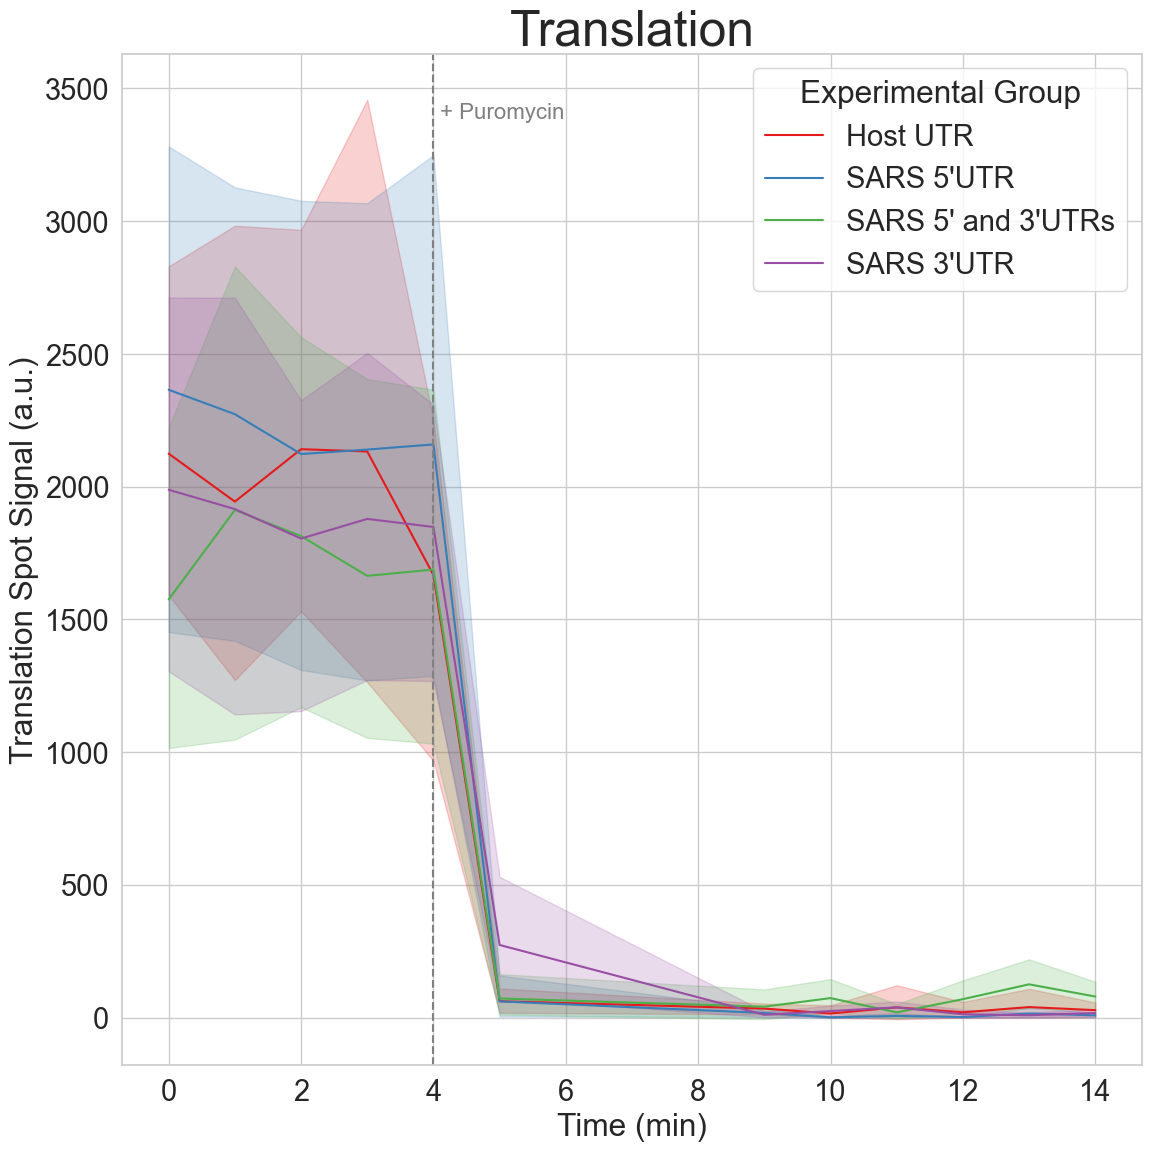

In [12]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")

# Define the new labels for the legend
new_labels = ["Host UTR", "SARS 5'UTR", "SARS 5' and 3'UTRs", "SARS 3'UTR"]

# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(12, 12))

# Line plot with 't' as the x-axis and 'Average Signal' as the y-axis
sns.lineplot(x="t", y="Average Signal", hue="Experimental_Group", 
             data=average_signal_df, ax=ax1, palette='Set1')

# Set axis labels and title
ax1.set_ylabel('Translation Spot Signal (a.u.)')
ax1.set_title('Translation', fontsize=36)
ax1.set_xlabel('Time (min)')

# Customize legend with new labels
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles=handles, labels=new_labels, title='Experimental Group')

# Add a dotted vertical line at t=4 with label "+ Puromycin"
ax1.axvline(x=4, color='grey', linestyle='--', linewidth=1.5)
ax1.text(4.1, ax1.get_ylim()[1] * 0.95, "+ Puromycin", color='grey', fontsize=16, verticalalignment='top')

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Puromycin Translation Signal Combined.svg")
filename_png_translation = os.path.join(save_directory, "Puromycin Translation Signal Combined.png")
fig1.savefig(filename_svg_translation, format='svg', bbox_inches='tight')
fig1.savefig(filename_png_translation, format='png', bbox_inches='tight')


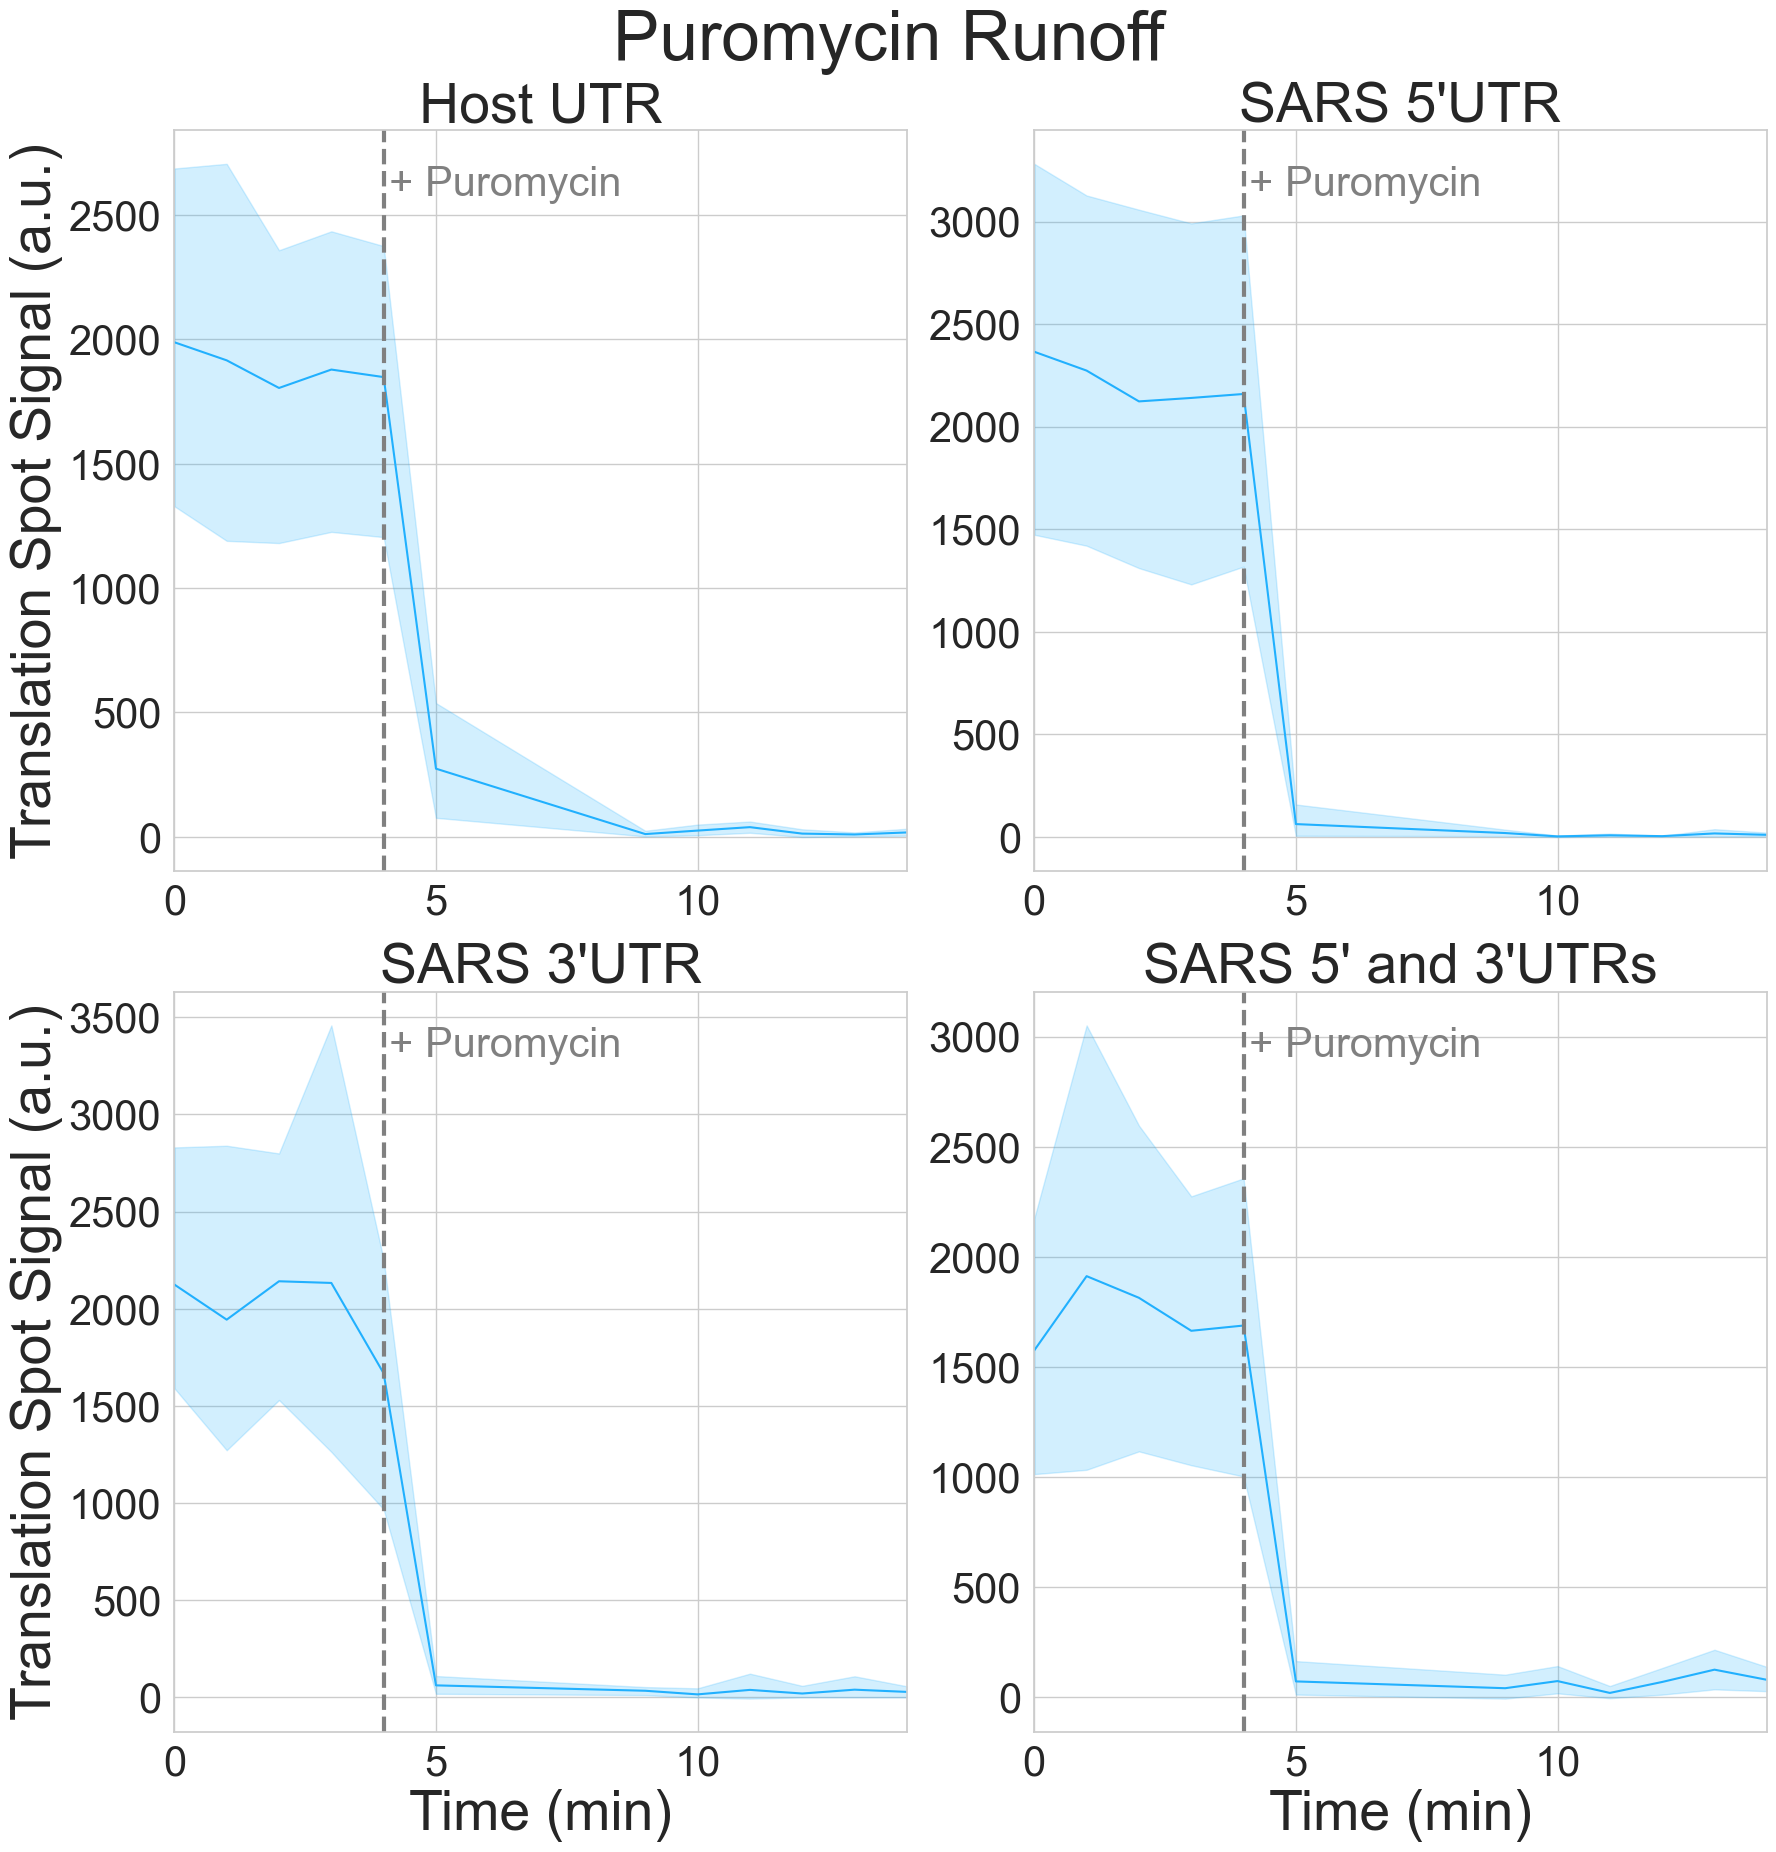

In [66]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.2)
sns.set_style("whitegrid")

# Define the mapping of experimental groups to their new labels for subplot titles
group_label_mapping = {
    "SARS_CTRL": "Host UTR",
    "SARS_5'UTR": "SARS 5'UTR",
    "SARS_3'UTR": "SARS 3'UTR",
    "SARS_5'UTR_3'UTR": "SARS 5' and 3'UTRs",
}

blue_palette = sns.color_palette(["#00D8D8"])

# Set up the 2x2 grid plot
fig, axes = plt.subplots(2, 2, figsize=(18, 18))
fig.suptitle("Puromycin Runoff", fontsize=50, y=1.03)

# Loop through each experimental group and plot the data in a subplot
for idx, ((group, label), ax) in enumerate(zip(group_label_mapping.items(), axes.flatten())):
    # Filter the data for the current experimental group
    subset_data = average_signal_df[average_signal_df['Experimental_Group'] == group]
    
    # Plot the line plot for the current experimental group
    sns.lineplot(x="t", y="Average Signal", data=subset_data, ax=ax, color="#21B0FE")
    ax.tick_params(axis='both', which='major', labelsize=30)
    
    # Set axis labels and title for each subplot
    if idx % 2 == 0:  # Set ylabel only for the first plot in each row
        ax.set_ylabel("Translation Spot Signal (a.u.)", fontsize=40)
    else:
        ax.set_ylabel("")
        
    if idx >= 2:  # Set xlabel only for the last row in each column
        ax.set_xlabel("Time (min)", fontsize=40)
    else:
        ax.set_xlabel("")
        
    ax.set_title(label, fontsize=40)
    ax.set_xlim(0, 14)
    
    # Add a vertical line at t=4 with label "+ Puromycin"
    ax.axvline(x=4, color='grey', linestyle='--', linewidth=3)
    ax.text(4.1, ax.get_ylim()[1] * 0.95, "+ Puromycin", color='grey', fontsize=30, verticalalignment='top')

# Adjust layout and show the plot
plt.tight_layout(rect=[0, 0, 1, 1.05])
plt.show()

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Puromycin Translation Signal Grid.svg")
filename_png_translation = os.path.join(save_directory, "Puromycin Translation Signal Grid.png")
fig.savefig(filename_svg_translation, format='svg', bbox_inches='tight')
fig.savefig(filename_png_translation, format='png', bbox_inches='tight')


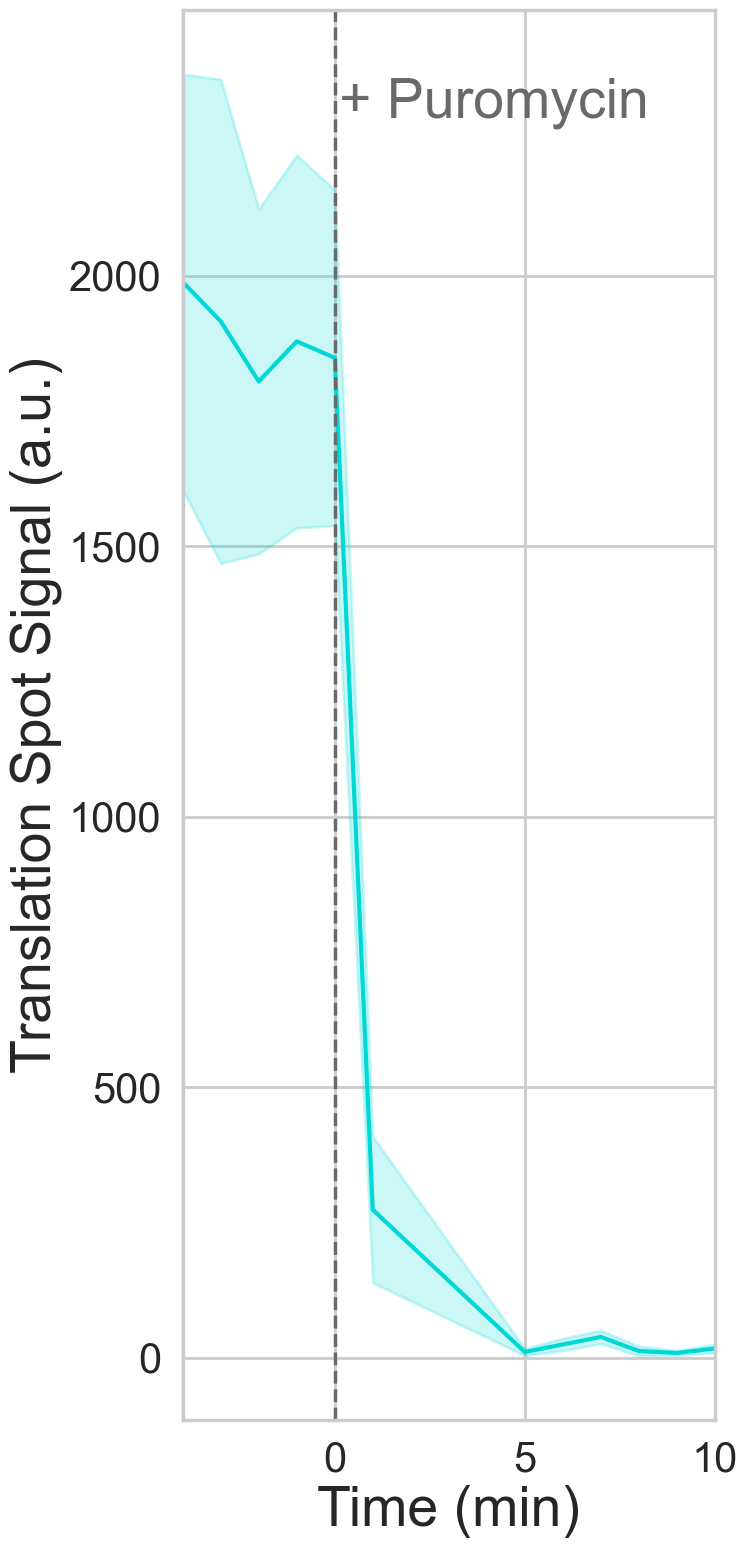

In [15]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_context("poster")
sns.set_style("whitegrid")

data = average_signal_df[
    average_signal_df["Experimental_Group"] == "SARS_CTRL"
].copy()

data["t_shifted"] = data["t"] - 4

# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16))

# Mean line with shaded SEM
sns.lineplot(
    x="t_shifted",
    y="Average Signal",
    data=data,
    ax=ax1,
    color="#00D8D8",
    estimator="mean",
    errorbar="se",
)

# Set axis labels
ax1.set_ylabel("Translation Spot Signal (a.u.)", fontsize=40)
ax1.set_xlabel("Time (min)", fontsize=40)
ax1.tick_params(axis="both", which="major", labelsize=30)
ax1.set_xlim(-4, 10)

# Remove legend
if ax1.get_legend() is not None:
    ax1.get_legend().remove()

# Add Puromycin line
ax1.axvline(
    x=0,
    color="dimgrey",
    linestyle="--",
    linewidth=2.5,
)

ax1.text(
    0.1,
    ax1.get_ylim()[1] * 0.95,
    "+ Puromycin",
    color="dimgrey",
    fontsize=40,
    verticalalignment="top",
)

plt.tight_layout()

# Save the figure
filename_svg_translation = os.path.join(
    save_directory,
    "Puromycin Translation Signal Host UTR.svg",
)

filename_png_translation = os.path.join(
    save_directory,
    "Puromycin Translation Signal Host UTR.png",
)

fig1.savefig(
    filename_svg_translation,
    format="svg",
    bbox_inches="tight",
)

fig1.savefig(
    filename_png_translation,
    format="png",
    bbox_inches="tight",
)

plt.show()

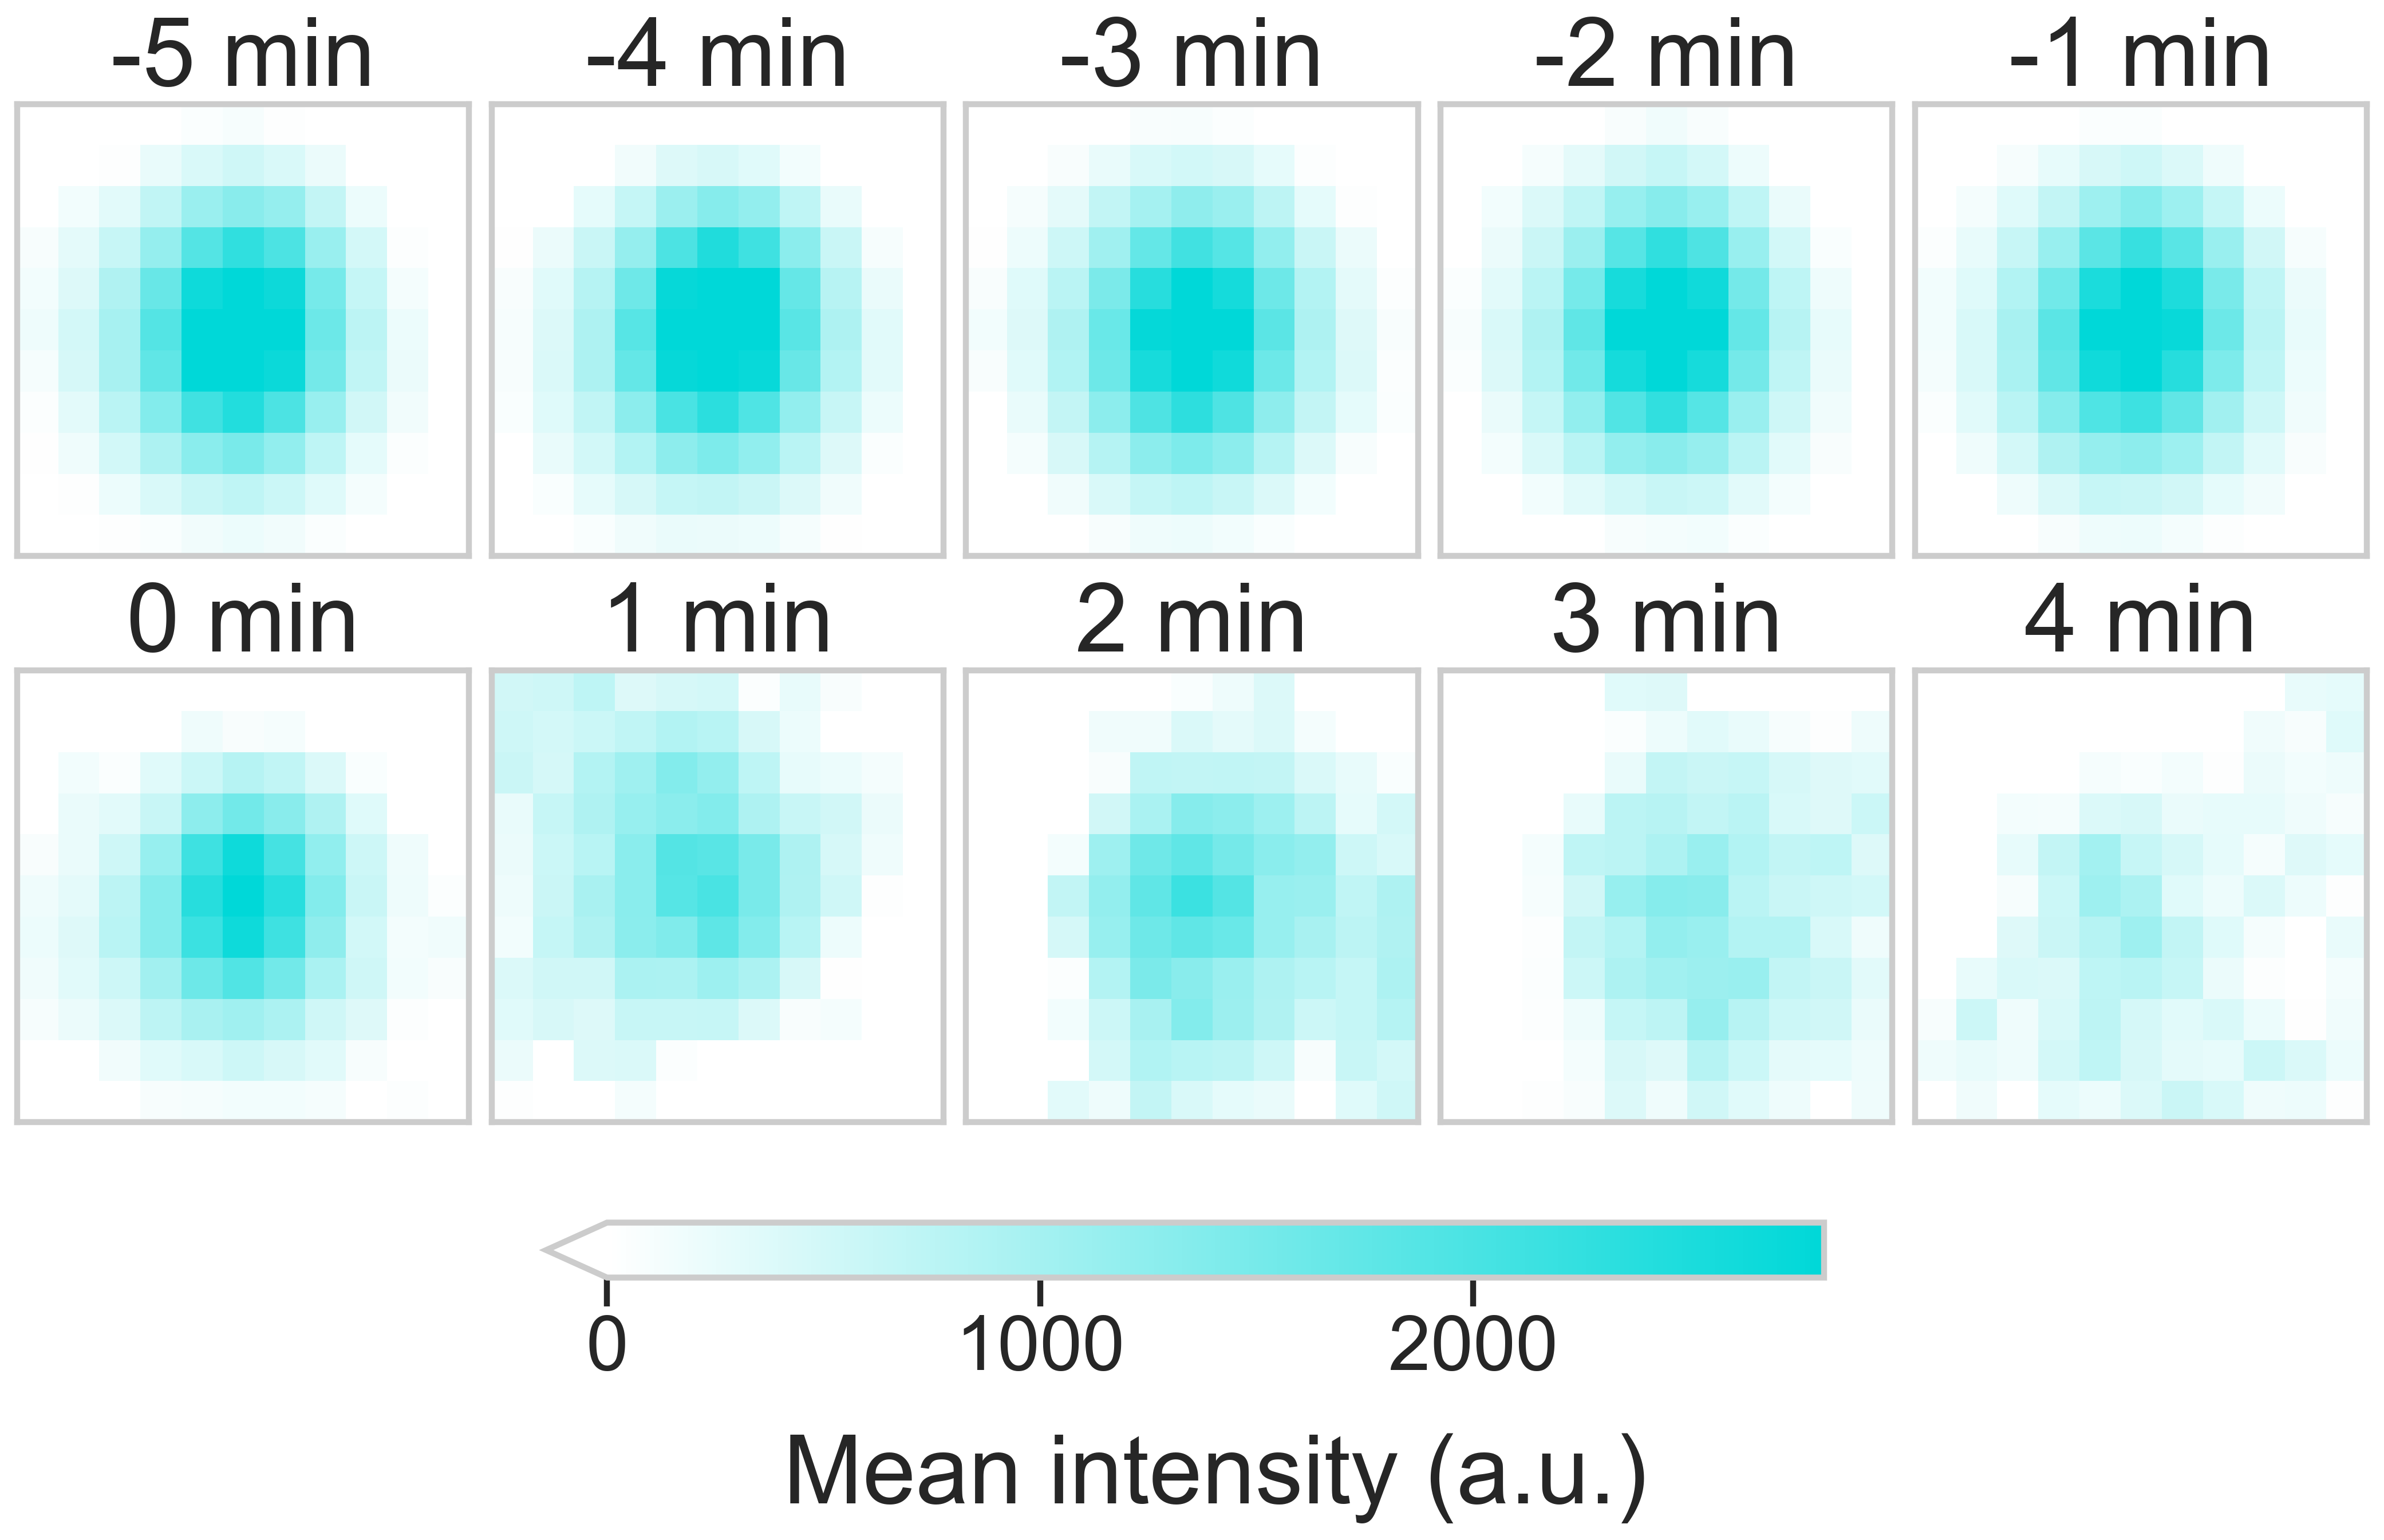

In [88]:
#Plot 1: Average puromycin translation signal intensity by time
cmap_cyan = white_to_hex_cmap("#00D8D8")

montage_avg_bestz_by_time(
    combined_ds,
    exp_g="SARS_CTRL",
    ch=1,
    time_points=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9,],
    savename="Puromycin Translation Signal Intensity",
    cmap=cmap_cyan,
    cols=5,
)

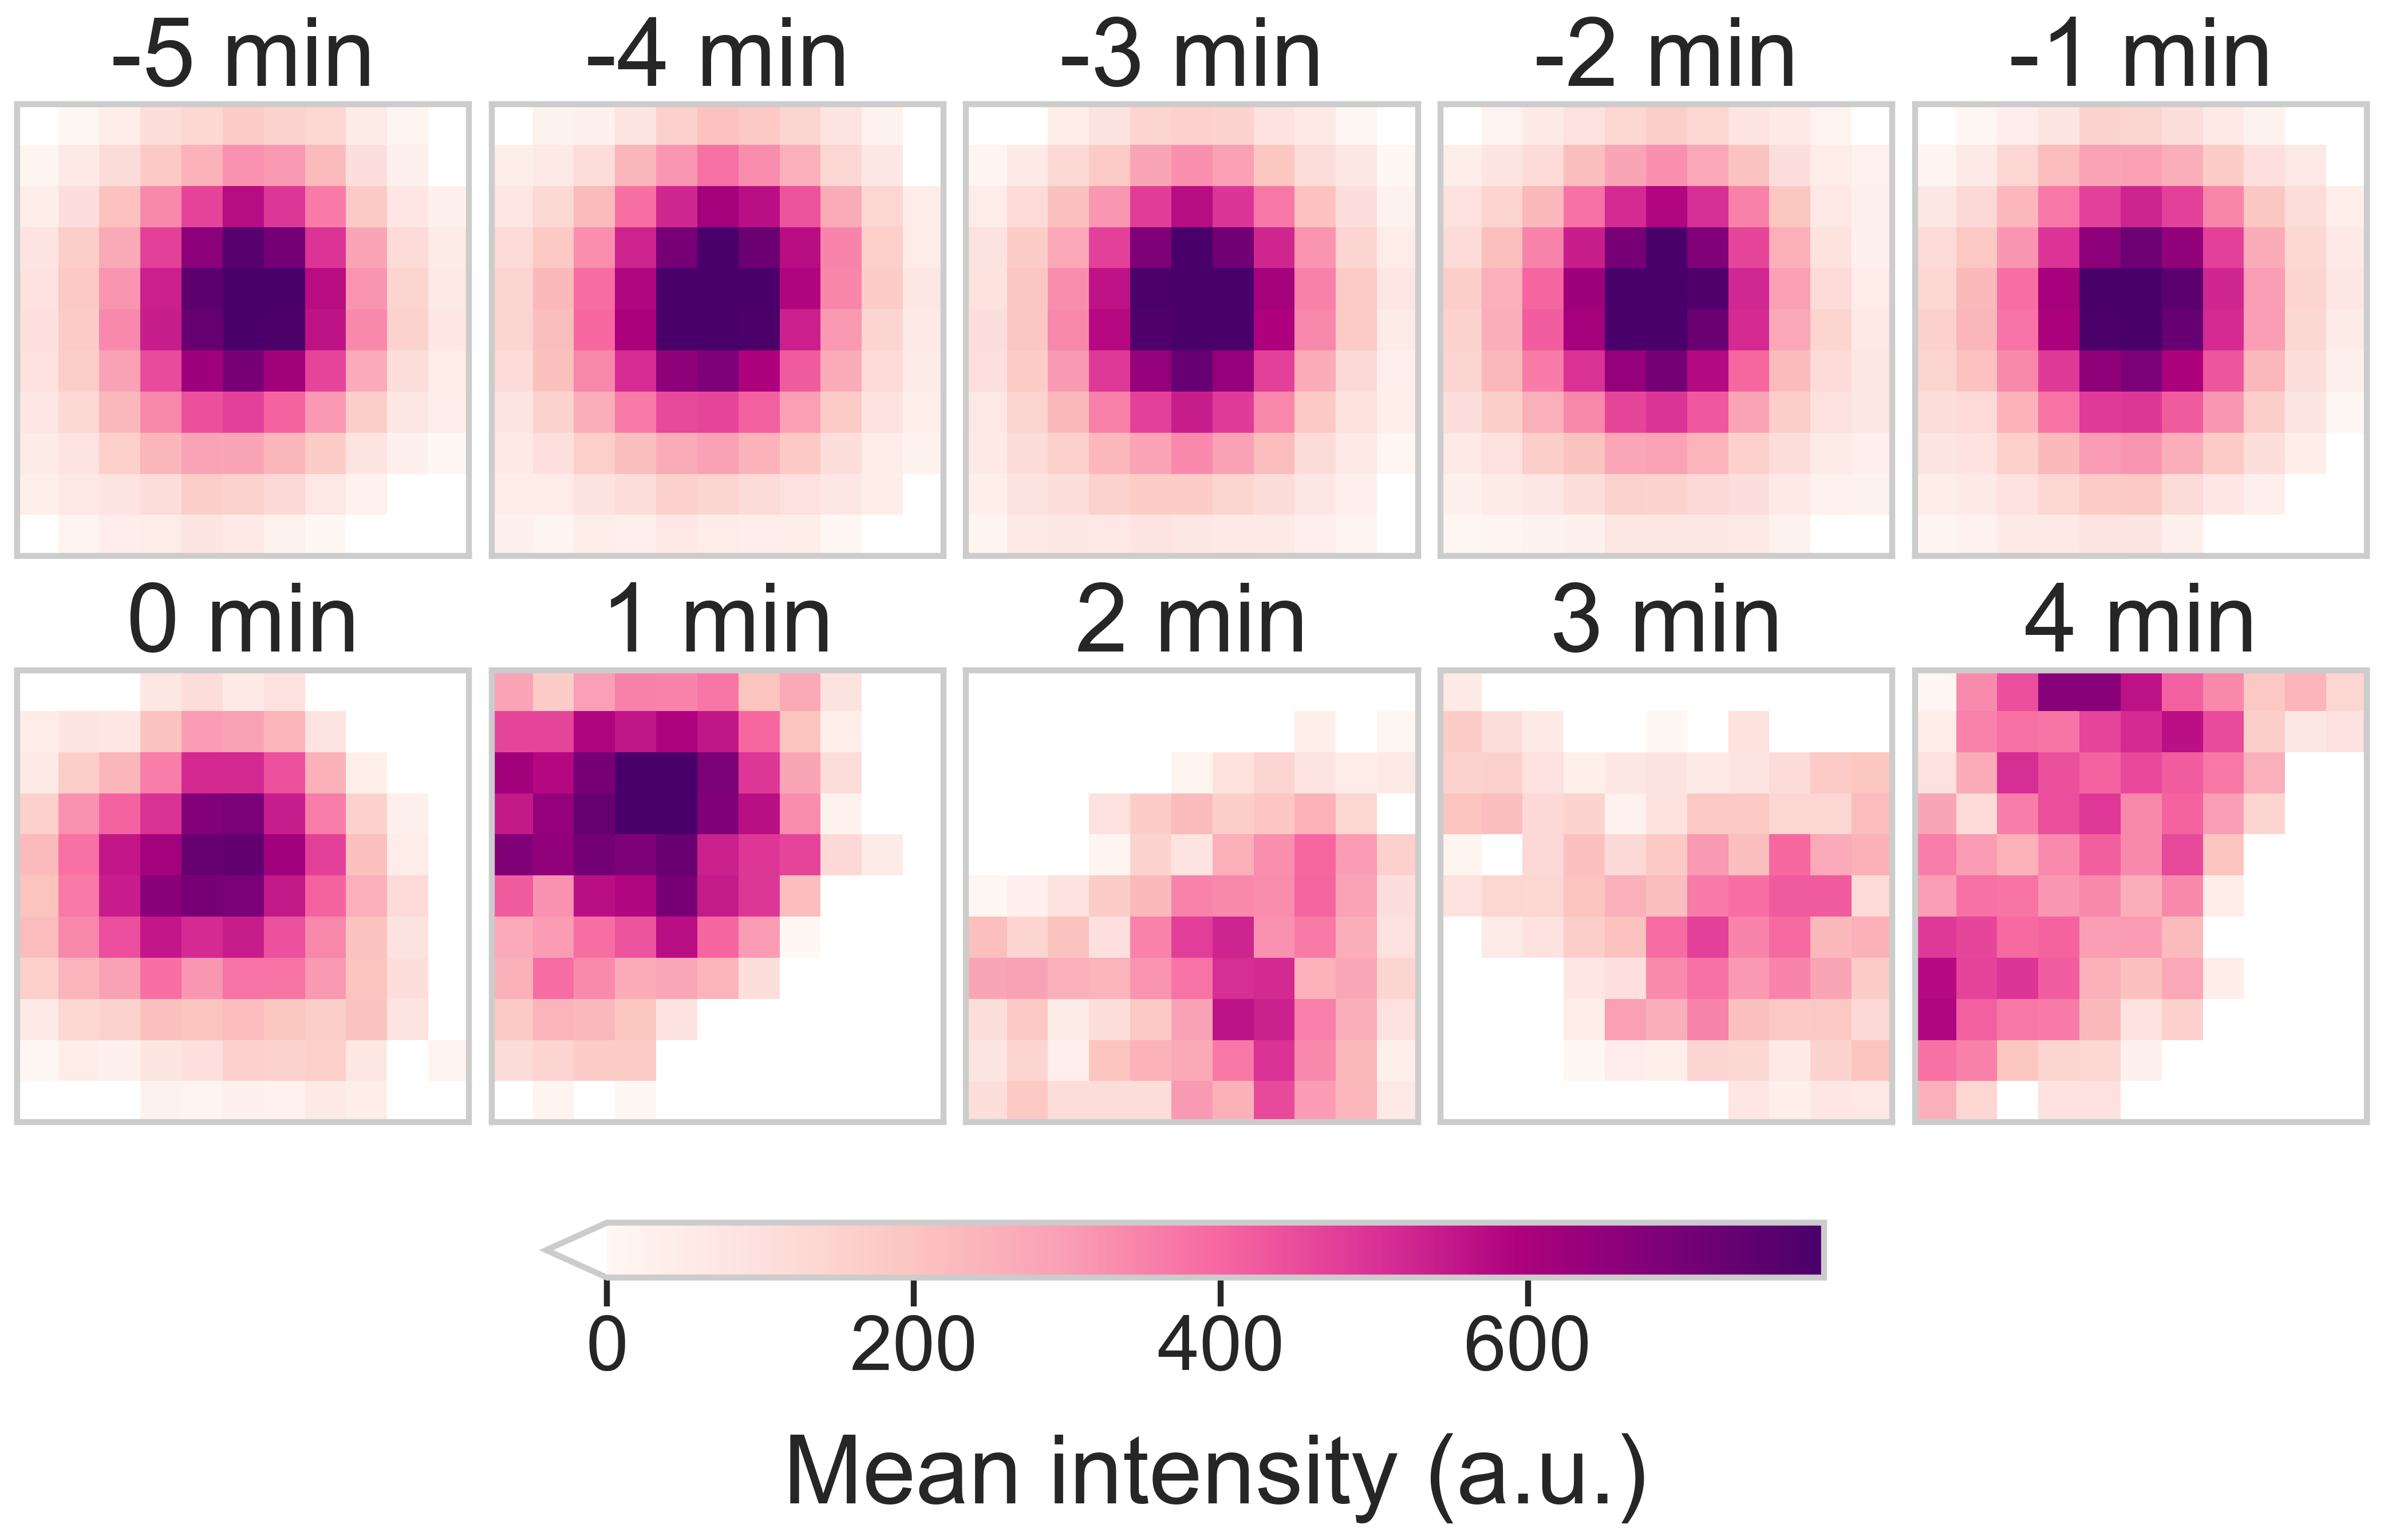

In [ ]:
#Plot 2: Average puromycin mRNA signal intensity by time
cmap_magenta = white_to_hex_cmap("#FF00FF")

montage_avg_bestz_by_time(
    combined_ds,
    exp_g="SARS_CTRL",
    ch=0,
    time_points=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9,],
    savename="Puromycin mRNA Signal Intensity",
    cmap="RdPu",
    cols=5,
)